# 公开1A3N蛋白质：从坐标到距离矩阵

问题：编号相隔很远的残基，在空间中也一定很远吗？

本笔记本使用包内固定公开实验结构，不进行蛋白质结构预测。AI协助代码组织与修改；请研究者阅读后逐步运行、复核。保持本笔记本、`analysis.py`、`data/`和`reference/`同级。

In [1]:
import sys
sys.dont_write_bytecode = True
from pathlib import Path
from analysis import run_analysis

assert Path("data/1A3N.pdb").is_file(), "请从案例文件夹运行，并保留data目录"
summary = run_analysis(Path("."))

Matplotlib is building the font cache; this may take a moment.


Input hashes and PDB/CSV coordinate checks passed.
Chain B: 145 C-alpha atoms; distance matrix 145 x 145, unit Å.
Unique pair counts at strict <6/<8/<10 Å: {6: 174, 8: 390, 10: 920}
Glu7-Ala129 C-alpha distance: 5.024620483181 Å
Maximum difference vs prior rounded matrix: 5e-09 Å
Validation passed. Files saved in results/.


## 查看实际计算结果

采用Cα距离严格小于阈值、PDB编号间隔大于2、每对只计一次的规则。距离单位为Å。

,chain,cutoff_angstrom,distance_rule,pdb_number_gap_rule,pair_rule,unique_pair_count
0,B,6,<,>2,i<j,174
1,B,8,<,>2,i<j,390
2,B,10,<,>2,i<j,920


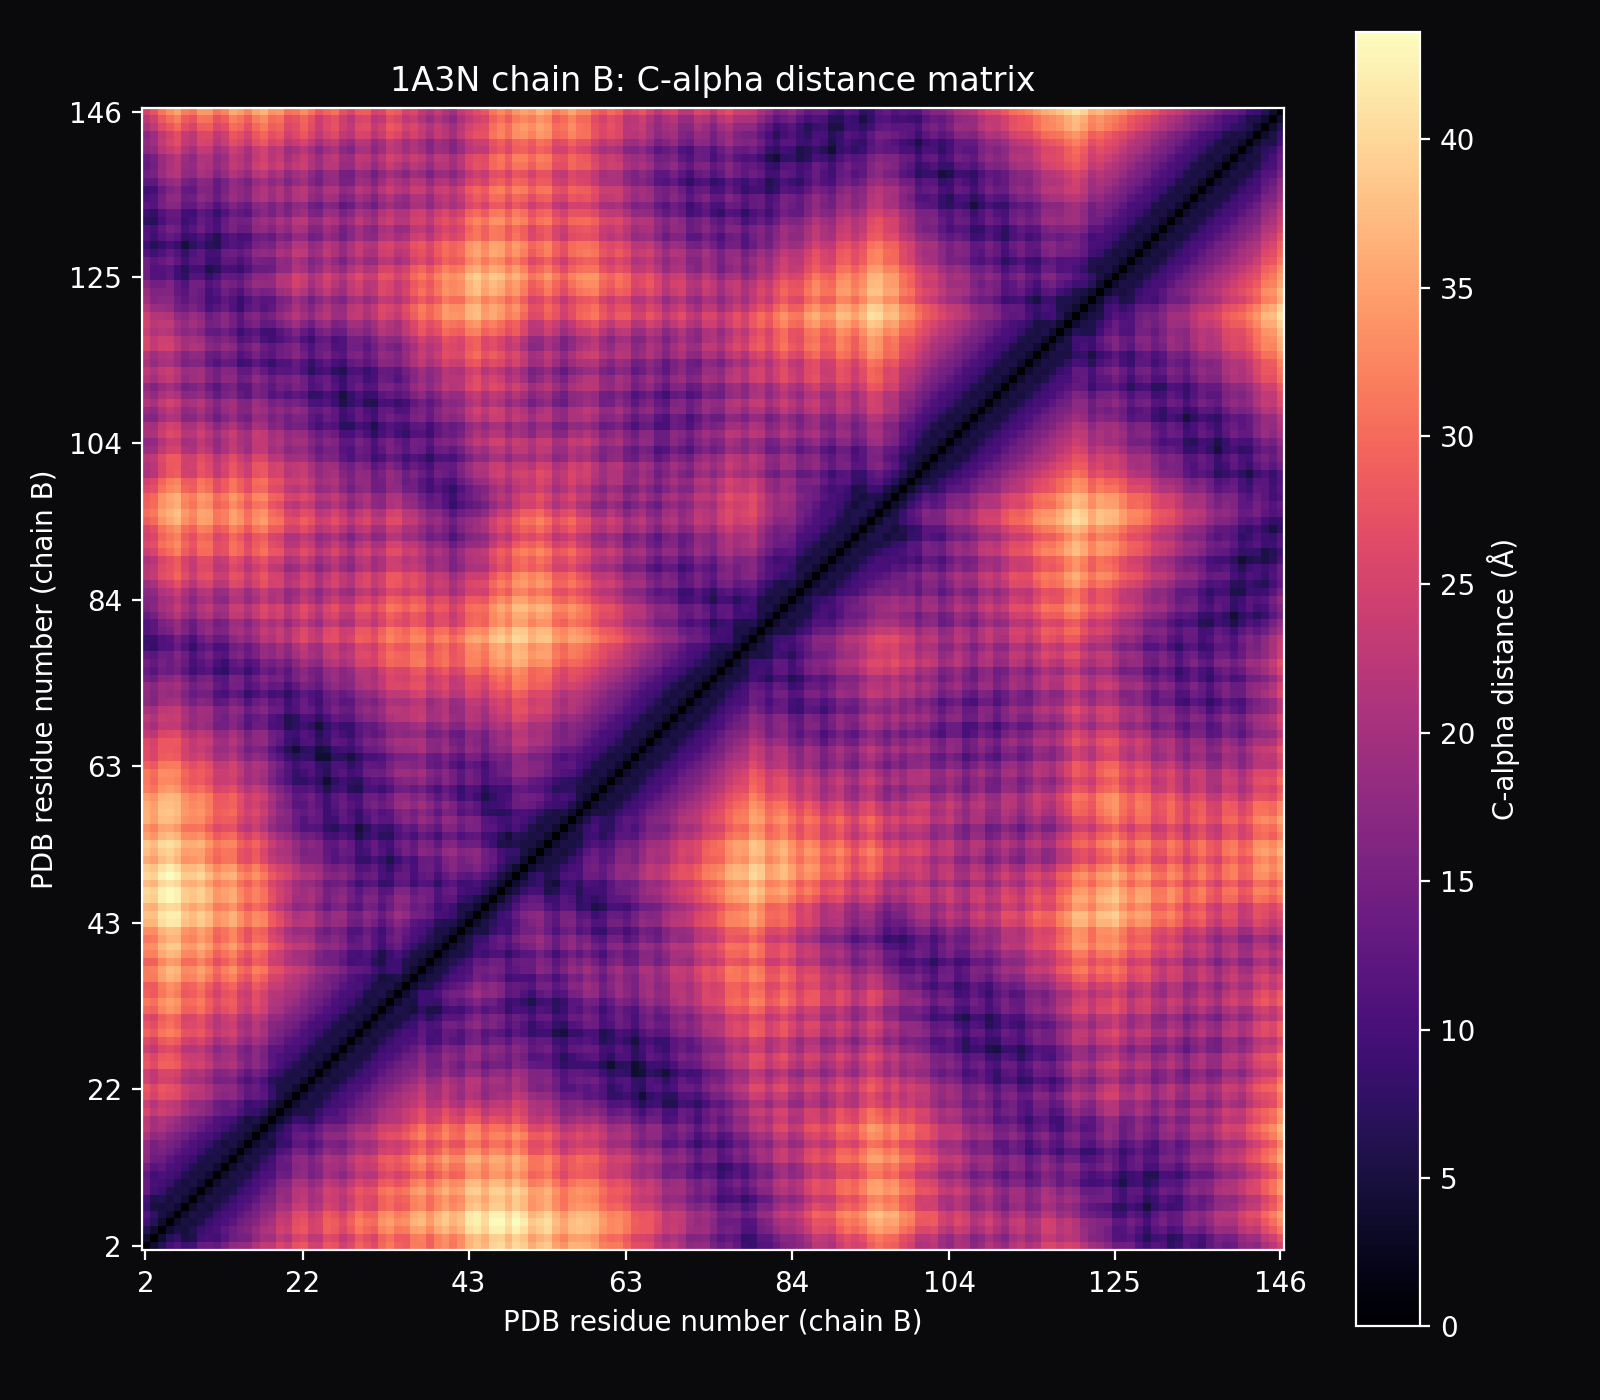

In [2]:
import pandas as pd
from IPython.display import display, Image, HTML

display(pd.read_csv("results/cutoff_counts.csv"))
display(Image(filename="results/distance-matrix.png"))

## 查看和复用输出

完整距离表、统计结果和SVG图均保存在`results/`。点击下方HTML文件可旋转查看真实三维结构；它需要联网加载3Dmol显示库，数值计算本身不需要联网。

In [3]:
for name in ("structure-view.html", "b_ca_distance_matrix_angstrom.csv", "distance-matrix.svg"):
    display(HTML(f'<a href="results/{name}" target="_blank">results/{name}</a>'))

## 结果说明

B链有145个Cα；6/8/10Å阈值分别得到174/390/920对。Glu7和Ala129的Cα相距约5.025Å。坐标来自公开实验结构，距离不是结合强度或功能结论。来源与固定快照哈希见`SOURCE-PROVENANCE.json`。